# CSET485 – AI and Society | Assignment 1
## German Credit Data | Roll number 564

Run all cells from top to bottom. This notebook implements the assignment's model comparison and four stress tests. Split: 70:30, `random_state=564`.

**Target interpretation:** The UCI German Credit data class is `1 = good credit risk` and `2 = bad credit risk`. For this assignment, `approval=1` means class 1 and `approval=0` means class 2. This is an operational proxy, not the bank's actual recorded approval decision. Use only numbers generated by running this notebook in your report.


## 1. Load data and libraries

In [19]:
# If needed, run: %pip install pandas numpy scikit-learn statsmodels matplotlib seaborn
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

RANDOM_SEED = 564
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"
columns = [
    "checking_status","duration","credit_history","purpose","credit_amount",
    "savings_status","employment","installment_rate","personal_status_sex",
    "other_debtors","residence_since","property","age","other_installment_plans",
    "housing","existing_credits","job","liable_people","telephone","foreign_worker","class"
]
try:
    df = pd.read_csv(DATA_URL, sep=r"\s+", header=None, names=columns)
except Exception as exc:
    raise RuntimeError("Dataset download failed. Check internet access or replace DATA_URL with your local german.data path.") from exc

print("Dataset shape:", df.shape)
display(df.head())
print("Original class counts:")
display(df["class"].value_counts().sort_index())


Dataset shape: (1000, 21)


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,existing_credits,job,liable_people,telephone,foreign_worker,class
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


Original class counts:


,count
class,
1,700
2,300


## 2. Preprocessing and documentation

Missing values:


,0
checking_status,0
duration,0
credit_history,0
purpose,0
credit_amount,0
savings_status,0
employment,0
installment_rate,0
personal_status_sex,0
other_debtors,0


Duplicate rows: 0
Numeric features: ['duration', 'credit_amount', 'installment_rate', 'residence_since', 'age', 'existing_credits', 'liable_people']
Categorical features: ['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'personal_status_sex', 'other_debtors', 'property', 'other_installment_plans', 'housing', 'job', 'telephone', 'foreign_worker']
Target: 1=good-credit-risk approval proxy; 0=bad-credit-risk rejection proxy

Preprocessing record for the report:
1. Missing values are inspected; pipeline imputes numeric columns with the median and
   categorical columns with the most frequent category.
2. Categorical attributes are one-hot encoded; unknown test categories are ignored.
3. Numeric features are standardized using training-set statistics.
4. Numeric outliers are inspected below. No observations are automatically removed because
   high credit amounts/durations may be meaningful; scaling is not outlier removal.
5. The split happens before fitting 

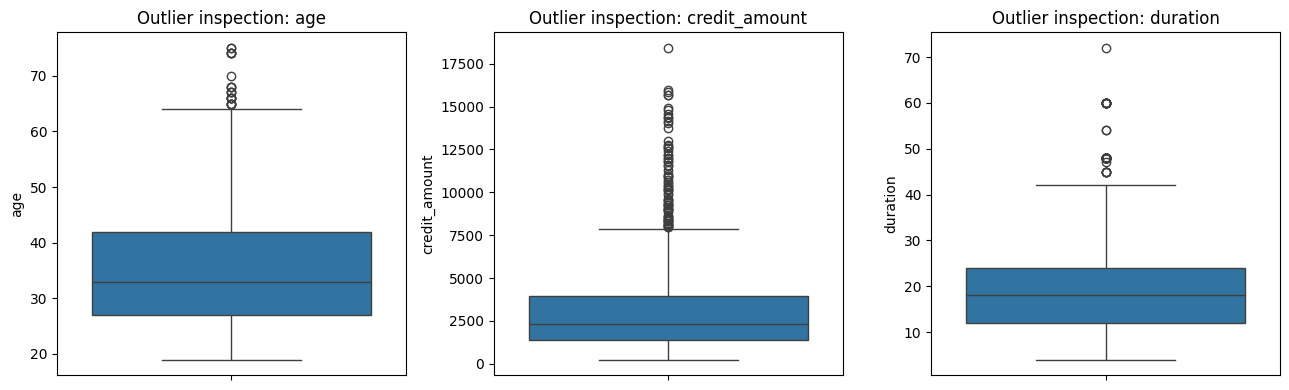

In [20]:
df["approval"] = (df["class"] == 1).astype(int)
df["gender_group"] = df["personal_status_sex"].map({
    "A91":"Male", "A93":"Male", "A94":"Male", "A92":"Female", "A95":"Female"
})

print("Missing values:")
display(df.isna().sum().sort_values(ascending=False).head(10))
print("Duplicate rows:", int(df.duplicated().sum()))

# Exclude original class, target, and derived sensitive-group column from predictors.
X = df.drop(columns=["class", "approval", "gender_group"])
y = df["approval"].astype(int)
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Target: 1=good-credit-risk approval proxy; 0=bad-credit-risk rejection proxy")
print("""
Preprocessing record for the report:
1. Missing values are inspected; pipeline imputes numeric columns with the median and
   categorical columns with the most frequent category.
2. Categorical attributes are one-hot encoded; unknown test categories are ignored.
3. Numeric features are standardized using training-set statistics.
4. Numeric outliers are inspected below. No observations are automatically removed because
   high credit amounts/durations may be meaningful; scaling is not outlier removal.
5. The split happens before fitting preprocessing, preventing test-set leakage.
""")
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, ["age", "credit_amount", "duration"]):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title("Outlier inspection: " + col)
plt.tight_layout()
plt.show()


## 3. Split data and fit both models

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_SEED, stratify=y
)
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Model A: OLS linear regression predicts the binary target as a numeric value.
model_a = Pipeline([("preprocessor", preprocessor), ("regressor", LinearRegression())])
model_a.fit(X_train, y_train)
pred_a = model_a.predict(X_test)

# Model B: logistic regression predicts approval probabilities.
model_b = Pipeline([("preprocessor", preprocessor),
                    ("classifier", LogisticRegression(max_iter=3000, random_state=RANDOM_SEED))])
model_b.fit(X_train, y_train)
pred_b_prob = model_b.predict_proba(X_test)[:, 1]

print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("OLS prediction range:", round(float(pred_a.min()), 4), "to", round(float(pred_a.max()), 4))
print("Logistic probability range:", round(float(pred_b_prob.min()), 4), "to", round(float(pred_b_prob.max()), 4))
print("OLS median predicted value:", round(float(np.median(pred_a)), 6))


Train rows: 700 | Test rows: 300
OLS prediction range: 0.0529 to 1.2958
Logistic probability range: 0.0766 to 0.9934
OLS median predicted value: 0.750274


## 4. Part 1 — Threshold comparison

In [22]:
threshold_a = float(np.median(pred_a))
class_a = (pred_a >= threshold_a).astype(int)
class_b = (pred_b_prob >= 0.5).astype(int)
cm = confusion_matrix(class_a, class_b, labels=[0, 1])
print("Agreement matrix (rows=OLS threshold class; columns=logistic class):")
display(pd.DataFrame(cm, index=["OLS class 0", "OLS class 1"], columns=["Logistic class 0", "Logistic class 1"]))
mismatch = class_a != class_b
print(f"Mismatched cases: {int(mismatch.sum())}/{len(mismatch)} = {100*mismatch.mean():.2f}%")
print(f"OLS median threshold={threshold_a:.6f}; logistic threshold=0.500000")
print("\nLogistic model evaluation against actual approval proxy:")
print("Accuracy:", round(accuracy_score(y_test, class_b), 4))
print("Precision:", round(precision_score(y_test, class_b, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, class_b, zero_division=0), 4))
print("F1:", round(f1_score(y_test, class_b, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, pred_b_prob), 4))
part1_results = pd.DataFrame({
    "actual_approval": y_test.to_numpy(),
    "ols_prediction": pred_a,
    "ols_class_median": class_a,
    "logistic_probability": pred_b_prob,
    "logistic_class_0_5": class_b,
    "mismatch": mismatch
}, index=y_test.index)
display(part1_results.head(10))


Agreement matrix (rows=OLS threshold class; columns=logistic class):


,Logistic class 0,Logistic class 1
OLS class 0,53,97
OLS class 1,0,150


Mismatched cases: 97/300 = 32.33%
OLS median threshold=0.750274; logistic threshold=0.500000

Logistic model evaluation against actual approval proxy:
Accuracy: 0.75
Precision: 0.7733
Recall: 0.9095
F1: 0.8359
ROC-AUC: 0.7879


,actual_approval,ols_prediction,ols_class_median,logistic_probability,logistic_class_0_5,mismatch
531,0,0.508884,0,0.464073,0,False
114,1,0.744239,0,0.831640,1,True
185,1,0.954345,1,0.945857,1,False
437,1,0.914516,1,0.940123,1,False
840,0,0.469318,0,0.424199,0,False
757,0,1.124589,1,0.980467,1,False
254,1,0.962950,1,0.950642,1,False
230,0,0.664384,0,0.682946,1,True
798,1,0.731083,0,0.831412,1,True
679,1,0.810521,1,0.870226,1,False


## 5. Part 2.1 — Subgroup effect / Simpson's paradox hunt

In [23]:
# Key predictor: age. Controls: duration and credit_amount.
# Compare coefficients, p-values and confidence intervals for full, male and female data.
def fit_age_model(data, label):
    cols = ["age", "duration", "credit_amount"]
    temp = data[cols + ["approval"]].dropna().copy()
    design = sm.add_constant(temp[cols].astype(float), has_constant="add")
    try:
        fit = sm.Logit(temp["approval"].astype(int), design).fit(disp=False, maxiter=300)
        ci = fit.conf_int()
        return {"group":label, "n":len(temp), "age_coef":float(fit.params["age"]),
                "age_p_value":float(fit.pvalues["age"]), "age_CI_low":float(ci.loc["age",0]),
                "age_CI_high":float(ci.loc["age",1]),
                "duration_coef":float(fit.params["duration"]),
                "credit_amount_coef":float(fit.params["credit_amount"])}
    except Exception as e:
        return {"group":label, "n":len(temp), "error":str(e)}

simpson_table = pd.DataFrame([
    fit_age_model(df, "Full dataset"),
    fit_age_model(df[df["gender_group"]=="Male"], "Male"),
    fit_age_model(df[df["gender_group"]=="Female"], "Female")
])
display(simpson_table)
if "age_coef" in simpson_table and simpson_table["age_coef"].notna().sum() == 3:
    signs = np.sign(simpson_table["age_coef"].to_numpy())
    print("Sign reversal detected." if signs.min() < 0 < signs.max()
          else "No sign reversal in this specification. Report coefficient magnitude, p-values and confidence intervals honestly.")


,group,n,age_coef,age_p_value,age_CI_low,age_CI_high,duration_coef,credit_amount_coef
0,Full dataset,1000,0.018725,0.004975,0.005658,0.031792,-0.033137,-0.000029
1,Male,690,0.005328,0.512928,-0.010633,0.021290,-0.032800,-0.000033
2,Female,310,0.036466,0.003116,0.012288,0.060645,-0.040128,-0.000026


No sign reversal in this specification. Report coefficient magnitude, p-values and confidence intervals honestly.


## 6. Part 2.2 — Omitted-variable bias

In [24]:
# Part 2.2: Full-feature vs reduced logistic regression
# Full model uses all original input features.
# Reduced model removes checking_status.

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Target and all original predictors
y_ovb = df["approval"].astype(int)

X_full_ovb = df.drop(
    columns=["class", "approval", "gender_group"]
).copy()

# Reduced model deliberately omits checking_status
X_reduced_ovb = X_full_ovb.drop(
    columns=["checking_status"]
)

def fit_full_logistic(X_input):
    numeric_cols = X_input.select_dtypes(
        include=["number"]
    ).columns.tolist()

    categorical_cols = X_input.select_dtypes(
        exclude=["number"]
    ).columns.tolist()

    preprocessing = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_cols),

        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ))
        ]), categorical_cols)
    ])

    model = Pipeline([
        ("preprocessing", preprocessing),
        ("logistic", LogisticRegression(
            max_iter=5000,
            C=1.0,
            random_state=564
        ))
    ])

    model.fit(X_input, y_ovb)

    feature_names = (
        model.named_steps["preprocessing"]
        .get_feature_names_out()
    )

    coefficients = model.named_steps["logistic"].coef_[0]

    return model, dict(zip(feature_names, coefficients))


# Fit both models on the same dataset
full_model, full_coef = fit_full_logistic(X_full_ovb)
reduced_model, reduced_coef = fit_full_logistic(X_reduced_ovb)

print("Original input features in full model:", X_full_ovb.shape[1])
print("Original input features in reduced model:", X_reduced_ovb.shape[1])
print("Omitted variable: checking_status")

# Compare at least four shared predictors
predictors = [
    "age",
    "duration",
    "credit_amount",
    "installment_rate"
]

rows = []

for predictor in predictors:
    key = f"num__{predictor}"

    before = float(full_coef[key])
    after = float(reduced_coef[key])

    absolute_change = abs(after - before)

    percentage_change = (
        (after - before) / abs(before) * 100
        if not np.isclose(before, 0)
        else np.nan
    )

    magnitude_change_percent = (
        (abs(after) - abs(before)) / abs(before) * 100
        if not np.isclose(before, 0)
        else np.nan
    )

    rows.append({
        "predictor": predictor,
        "full_model_coefficient": before,
        "reduced_model_coefficient": after,
        "absolute_change": absolute_change,
        "percentage_change": percentage_change,
        "magnitude_change_percent": magnitude_change_percent
    })

ovb_table = pd.DataFrame(rows)

display(ovb_table.round(6))

largest_shift = ovb_table.loc[
    ovb_table["absolute_change"].idxmax()
]

print("Largest absolute coefficient shift:", largest_shift["predictor"])
print(
    "Largest absolute shift value:",
    round(largest_shift["absolute_change"], 6)
)

# Save this corrected comparison for the report
ovb_table.to_csv("part2_2_full_feature_ovb.csv", index=False)
print("Saved: part2_2_full_feature_ovb.csv")

Original input features in full model: 20
Original input features in reduced model: 19
Omitted variable: checking_status


,predictor,full_model_coefficient,reduced_model_coefficient,absolute_change,percentage_change,magnitude_change_percent
0,age,0.156293,0.179915,0.023622,15.113808,15.113808
1,duration,-0.325445,-0.359191,0.033746,-10.369187,10.369187
2,credit_amount,-0.338689,-0.321498,0.017191,5.075826,-5.075826
3,installment_rate,-0.346094,-0.338859,0.007234,2.090311,-2.090311


Largest absolute coefficient shift: duration
Largest absolute shift value: 0.033746
Saved: part2_2_full_feature_ovb.csv


## 7. Part 2.3 — Confident wrong predictions / adversarial subset

In [25]:
adv = part1_results.copy()
adv["gender_group"] = df.loc[adv.index, "gender_group"]
adv["age"] = df.loc[adv.index, "age"]
adv["credit_amount"] = df.loc[adv.index, "credit_amount"]
adv["duration"] = df.loc[adv.index, "duration"]
fp = (adv["logistic_probability"] >= 0.75) & (adv["actual_approval"] == 0)
fn = (adv["logistic_probability"] <= 0.25) & (adv["actual_approval"] == 1)
adv["error_type"] = np.select([fp, fn],
    ["False positive: confident approval", "False negative: confident rejection"], default="")
wrong_confident = adv[adv["error_type"] != ""].copy()
print(f"High-confidence wrong predictions: {len(wrong_confident)}/{len(adv)} = {100*len(wrong_confident)/len(adv):.2f}% of test set")
print("False positives:", int(fp.sum()), "| False negatives:", int(fn.sum()))
adv50 = wrong_confident.sample(50, random_state=RANDOM_SEED) if len(wrong_confident)>50 else wrong_confident.copy()
print("Rows in adversarial subset:", len(adv50))
demo = pd.DataFrame({
    "adversarial_subset":[adv50["age"].mean() if len(adv50) else np.nan,
        (adv50["gender_group"]=="Female").mean()*100 if len(adv50) else np.nan,
        (adv50["gender_group"]=="Male").mean()*100 if len(adv50) else np.nan],
    "full_test_set":[adv["age"].mean(), (adv["gender_group"]=="Female").mean()*100,
        (adv["gender_group"]=="Male").mean()*100]
}, index=["Mean age (years)", "Female (%)", "Male (%)"])
display(demo)
if len(adv50):
    display(adv50["error_type"].value_counts().to_frame("count"))
    display(adv50[["age","credit_amount","duration","logistic_probability"]].describe())
    for col in ["checking_status","credit_history","purpose","employment","housing"]:
        print("Top categories:", col)
        display((df.loc[adv50.index,col].value_counts(normalize=True).head(5)*100).to_frame("percentage"))
    display(adv50)
else:
    print("No rows meet the specified conditions. Report zero; do not fabricate examples.")


High-confidence wrong predictions: 23/300 = 7.67% of test set
False positives: 22 | False negatives: 1
Rows in adversarial subset: 23


,adversarial_subset,full_test_set
Mean age (years),36.217391,35.49
Female (%),26.086957,33.00
Male (%),73.913043,67.00


,count
error_type,
False positive: confident approval,22
False negative: confident rejection,1


,age,credit_amount,duration,logistic_probability
count,23.000000,23.000000,23.000000,23.000000
mean,36.217391,4975.913043,20.695652,0.848235
std,9.543949,4182.665330,11.530335,0.154104
min,23.000000,745.000000,6.000000,0.213150
25%,29.000000,1600.500000,12.000000,0.803527
50%,34.000000,2775.000000,18.000000,0.869571
75%,42.000000,7471.500000,24.000000,0.936149
max,54.000000,14555.000000,48.000000,0.980467


Top categories: checking_status


...

Top categories: employment


,percentage
employment,
A73,43.478261
A75,21.739130
A74,17.391304
A72,13.043478
A71,4.347826


Top categories: housing


,percentage
housing,
A152,69.565217
A153,17.391304
A151,13.043478


,actual_approval,ols_prediction,ols_class_median,logistic_probability,logistic_class_0_5,mismatch,gender_group,age,credit_amount,duration,error_type
757,0,1.124589,1,0.980467,1,False,Male,39,1271,15,False positive: confident approval
936,0,0.851117,1,0.869571,1,False,Female,28,745,9,False positive: confident approval
92,0,1.022201,1,0.963263,1,False,Female,33,797,12,False positive: confident approval
118,0,0.693628,0,0.770833,1,True,Female,23,4281,33,False positive: confident approval
409,0,0.940359,1,0.937619,1,False,Male,28,939,12,False positive: confident approval
505,0,1.026144,1,0.953270,1,False,Male,27,1309,10,False positive: confident approval
796,0,0.982415,1,0.957947,1,False,Male,51,7511,18,False positive: confident approval
552,0,0.736605,0,0.791491,1,True,Male,34,6999,48,False positive: confident approval
236,0,0.899628,1,0.893227,1,False,Male,23,14555,6,False positive: confident approval
763,0,0.896375,1,0.911485,1,False,Male,30,12680,21,False positive: confident approval


## 8. Part 2.4 — Fairness metrics across thresholds

,threshold,DP_female_over_male,EO_min_TPR_FPR_ratio,PP_female_over_male,Male_selection_rate,Female_selection_rate,Male_TPR,Female_TPR,Male_FPR,Female_FPR,Male_PPV,Female_PPV
0,0.05,1.0000,1.0000,0.8505,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.7363,0.6263
1,0.15,0.9844,0.9741,0.8640,0.9851,0.9697,1.0000,1.0000,0.9434,0.9189,0.7475,0.6458
2,0.25,0.9530,0.9251,0.8781,0.9751,0.9293,1.0000,0.9839,0.9057,0.8378,0.7551,0.6630
3,0.35,0.9658,0.9327,0.8883,0.9204,0.8889,0.9595,0.9677,0.8113,0.7568,0.7676,0.6818
4,0.45,0.9797,0.9822,0.8924,0.8557,0.8384,0.9257,0.9516,0.6604,0.6486,0.7965,0.7108
5,0.55,0.9449,0.8891,0.9256,0.7910,0.7475,0.8784,0.9032,0.5472,0.4865,0.8176,0.7568
6,0.65,0.8928,0.7813,0.9555,0.7015,0.6263,0.8041,0.8065,0.4151,0.3243,0.8440,0.8065
7,0.75,0.8654,0.4213,1.0502,0.6070,0.5253,0.7095,0.7581,0.3208,0.1351,0.8607,0.9038
8,0.85,0.8078,0.5730,0.9993,0.4627,0.3737,0.5608,0.5323,0.1887,0.1081,0.8925,0.8919
9,0.95,0.7614,0.3581,1.0370,0.1990,0.1515,0.2432,0.2258,0.0755,0.0270,0.9000,0.9333


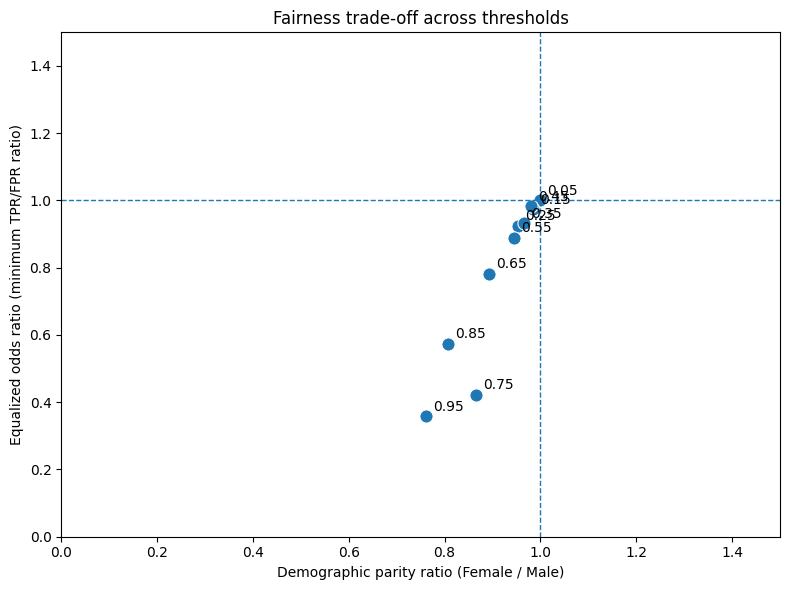

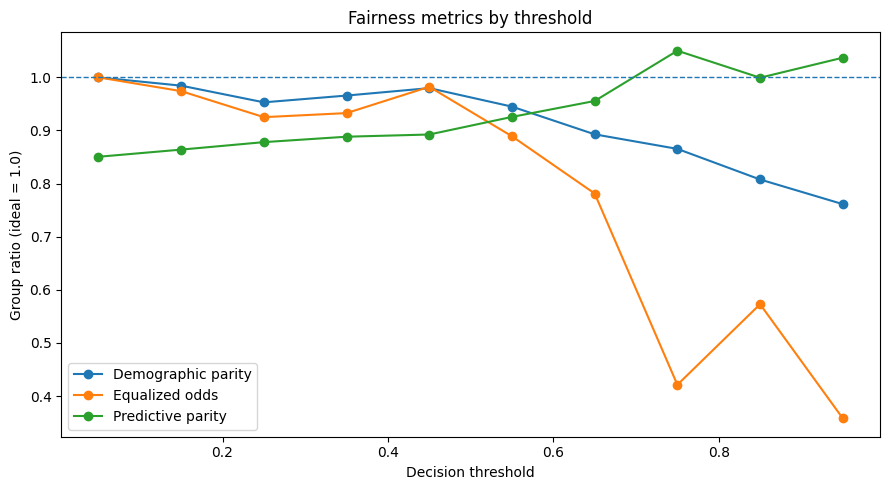

In [26]:
# Sensitive attribute: gender. Ratios are Female / Male; ideal ratio = 1.
fair = pd.DataFrame({"y":y_test.to_numpy(), "prob":pred_b_prob,
                     "gender_group":df.loc[y_test.index,"gender_group"].to_numpy()},
                    index=y_test.index).dropna(subset=["gender_group"])

def ratio(a,b):
    return np.nan if pd.isna(a) or pd.isna(b) or np.isclose(b,0) else a/b

def group_rates(sub, threshold):
    pred = (sub["prob"] >= threshold).astype(int)
    ytrue = sub["y"].astype(int)
    tp = int(((pred==1)&(ytrue==1)).sum())
    fn = int(((pred==0)&(ytrue==1)).sum())
    fp = int(((pred==1)&(ytrue==0)).sum())
    tn = int(((pred==0)&(ytrue==0)).sum())
    return {"selection":float(pred.mean()) if len(pred) else np.nan,
            "TPR":tp/(tp+fn) if tp+fn else np.nan,
            "FPR":fp/(fp+tn) if fp+tn else np.nan,
            "PPV":tp/(tp+fp) if tp+fp else np.nan}

thresholds = np.round(np.arange(0.05, 0.951, 0.10), 2)
rows = []
for t in thresholds:
    m = group_rates(fair[fair.gender_group=="Male"], t)
    f = group_rates(fair[fair.gender_group=="Female"], t)
    tpr_ratio, fpr_ratio = ratio(f["TPR"],m["TPR"]), ratio(f["FPR"],m["FPR"])
    eo = np.nanmin([tpr_ratio,fpr_ratio]) if not (np.isnan(tpr_ratio) and np.isnan(fpr_ratio)) else np.nan
    rows.append({"threshold":t, "DP_female_over_male":ratio(f["selection"],m["selection"]),
        "EO_min_TPR_FPR_ratio":eo, "PP_female_over_male":ratio(f["PPV"],m["PPV"]),
        "Male_selection_rate":m["selection"], "Female_selection_rate":f["selection"],
        "Male_TPR":m["TPR"], "Female_TPR":f["TPR"], "Male_FPR":m["FPR"],
        "Female_FPR":f["FPR"], "Male_PPV":m["PPV"], "Female_PPV":f["PPV"]})
fairness_table = pd.DataFrame(rows)
display(fairness_table.round(4))

plt.figure(figsize=(8,6))
sns.scatterplot(data=fairness_table, x="DP_female_over_male", y="EO_min_TPR_FPR_ratio", s=90)
for _, r in fairness_table.iterrows():
    if pd.notna(r["DP_female_over_male"]) and pd.notna(r["EO_min_TPR_FPR_ratio"]):
        plt.annotate(f'{r["threshold"]:.2f}', (r["DP_female_over_male"],r["EO_min_TPR_FPR_ratio"]),
                     xytext=(5,4), textcoords="offset points")
plt.axvline(1, linestyle="--", linewidth=1); plt.axhline(1, linestyle="--", linewidth=1)
plt.xlim(0,1.5); plt.ylim(0,1.5)
plt.xlabel("Demographic parity ratio (Female / Male)")
plt.ylabel("Equalized odds ratio (minimum TPR/FPR ratio)")
plt.title("Fairness trade-off across thresholds")
plt.tight_layout(); plt.show()

plt.figure(figsize=(9,5))
for col,label in [("DP_female_over_male","Demographic parity"),
                  ("EO_min_TPR_FPR_ratio","Equalized odds"),
                  ("PP_female_over_male","Predictive parity")]:
    plt.plot(fairness_table["threshold"],fairness_table[col],marker="o",label=label)
plt.axhline(1,linestyle="--",linewidth=1)
plt.xlabel("Decision threshold"); plt.ylabel("Group ratio (ideal = 1.0)")
plt.title("Fairness metrics by threshold"); plt.legend(); plt.tight_layout(); plt.show()


## 9. Export tables for report writing

In [27]:
part1_results.to_csv("part1_prediction_comparison.csv")
simpson_table.to_csv("part2_1_subgroup_coefficients.csv", index=False)
ovb_table.to_csv("part2_2_omitted_variable_bias.csv", index=False)
adv50.to_csv("part2_3_adversarial_subset.csv")
fairness_table.to_csv("part2_4_fairness_thresholds.csv", index=False)
print("CSV tables saved in the current notebook folder.")


CSV tables saved in the current notebook folder.


## 10. Submission checklist and interpretation notes
- Run all cells from top to bottom and save the notebook with outputs.
- Use generated results in the PDF; all eight Part 3 answers and Part 4 reflection require actual numbers.
- Do not claim Simpson's paradox unless the coefficients support it. If there is no sign reversal, compare effect sizes, p-values and confidence intervals as the assignment permits.
- Fairness ratios may be undefined when a denominator group rate is zero. Leave these as NaN and explain them.
- The original dataset labels good/bad credit risk, not actual recorded bank approval. State this limitation clearly.
- Upload the notebook to GitHub and include the link in the PDF.
